# Waste classification project

## Business understanding

In this notebook we are building a deep learning convolutional neural network (CNN) used for waste classification. We will building our own CNN model and we will be also fine tuning a pretrained model such as VGG16, for classifying different waste such as plastics, bio, and paper. The goal is to get an accuracy score of atleast 80% for our own CNN model and over 90% for the finetuned one. The model can be used for various different purposes and help with waste classification.

The project has strong use for real world problems. Many places suffer from excessive waste pollution and many recylcing senters and wasteplants could benefit from automated sorting. 



## Data Understanding

Next we need to choose an appropiate dataset. We installed many different datasets from kaggle and went through them. Many of them were pictures taken from webscraping. These pictures looked way too professionally made and they did not represent realworld circumstances. After looking at different datasets we found a suitable one, that had pictures of real trash and waste mixed with some of the studiolike pictures.

Link to the dataset: 
https://www.kaggle.com/datasets/glhdamar/new-trash-classfication-dataset

In [13]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import numpy as np
import matplotlib.pyplot as plt


In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("glhdamar/new-trash-classfication-dataset")

print("Path to dataset files:", path)

Path to dataset files: /Users/blendigraicevci/.cache/kagglehub/datasets/glhdamar/new-trash-classfication-dataset/versions/3


### Sample Pictures

Lets see a few pictures from different classes:

Classes: ['cardboard', 'e-waste', 'glass', 'metal', 'organic', 'paper', 'plastic', 'textile', 'trash']
cardboard: 893 images
e-waste: 993 images
glass: 948 images
metal: 901 images
organic: 967 images
paper: 853 images
plastic: 891 images
textile: 985 images
trash: 976 images


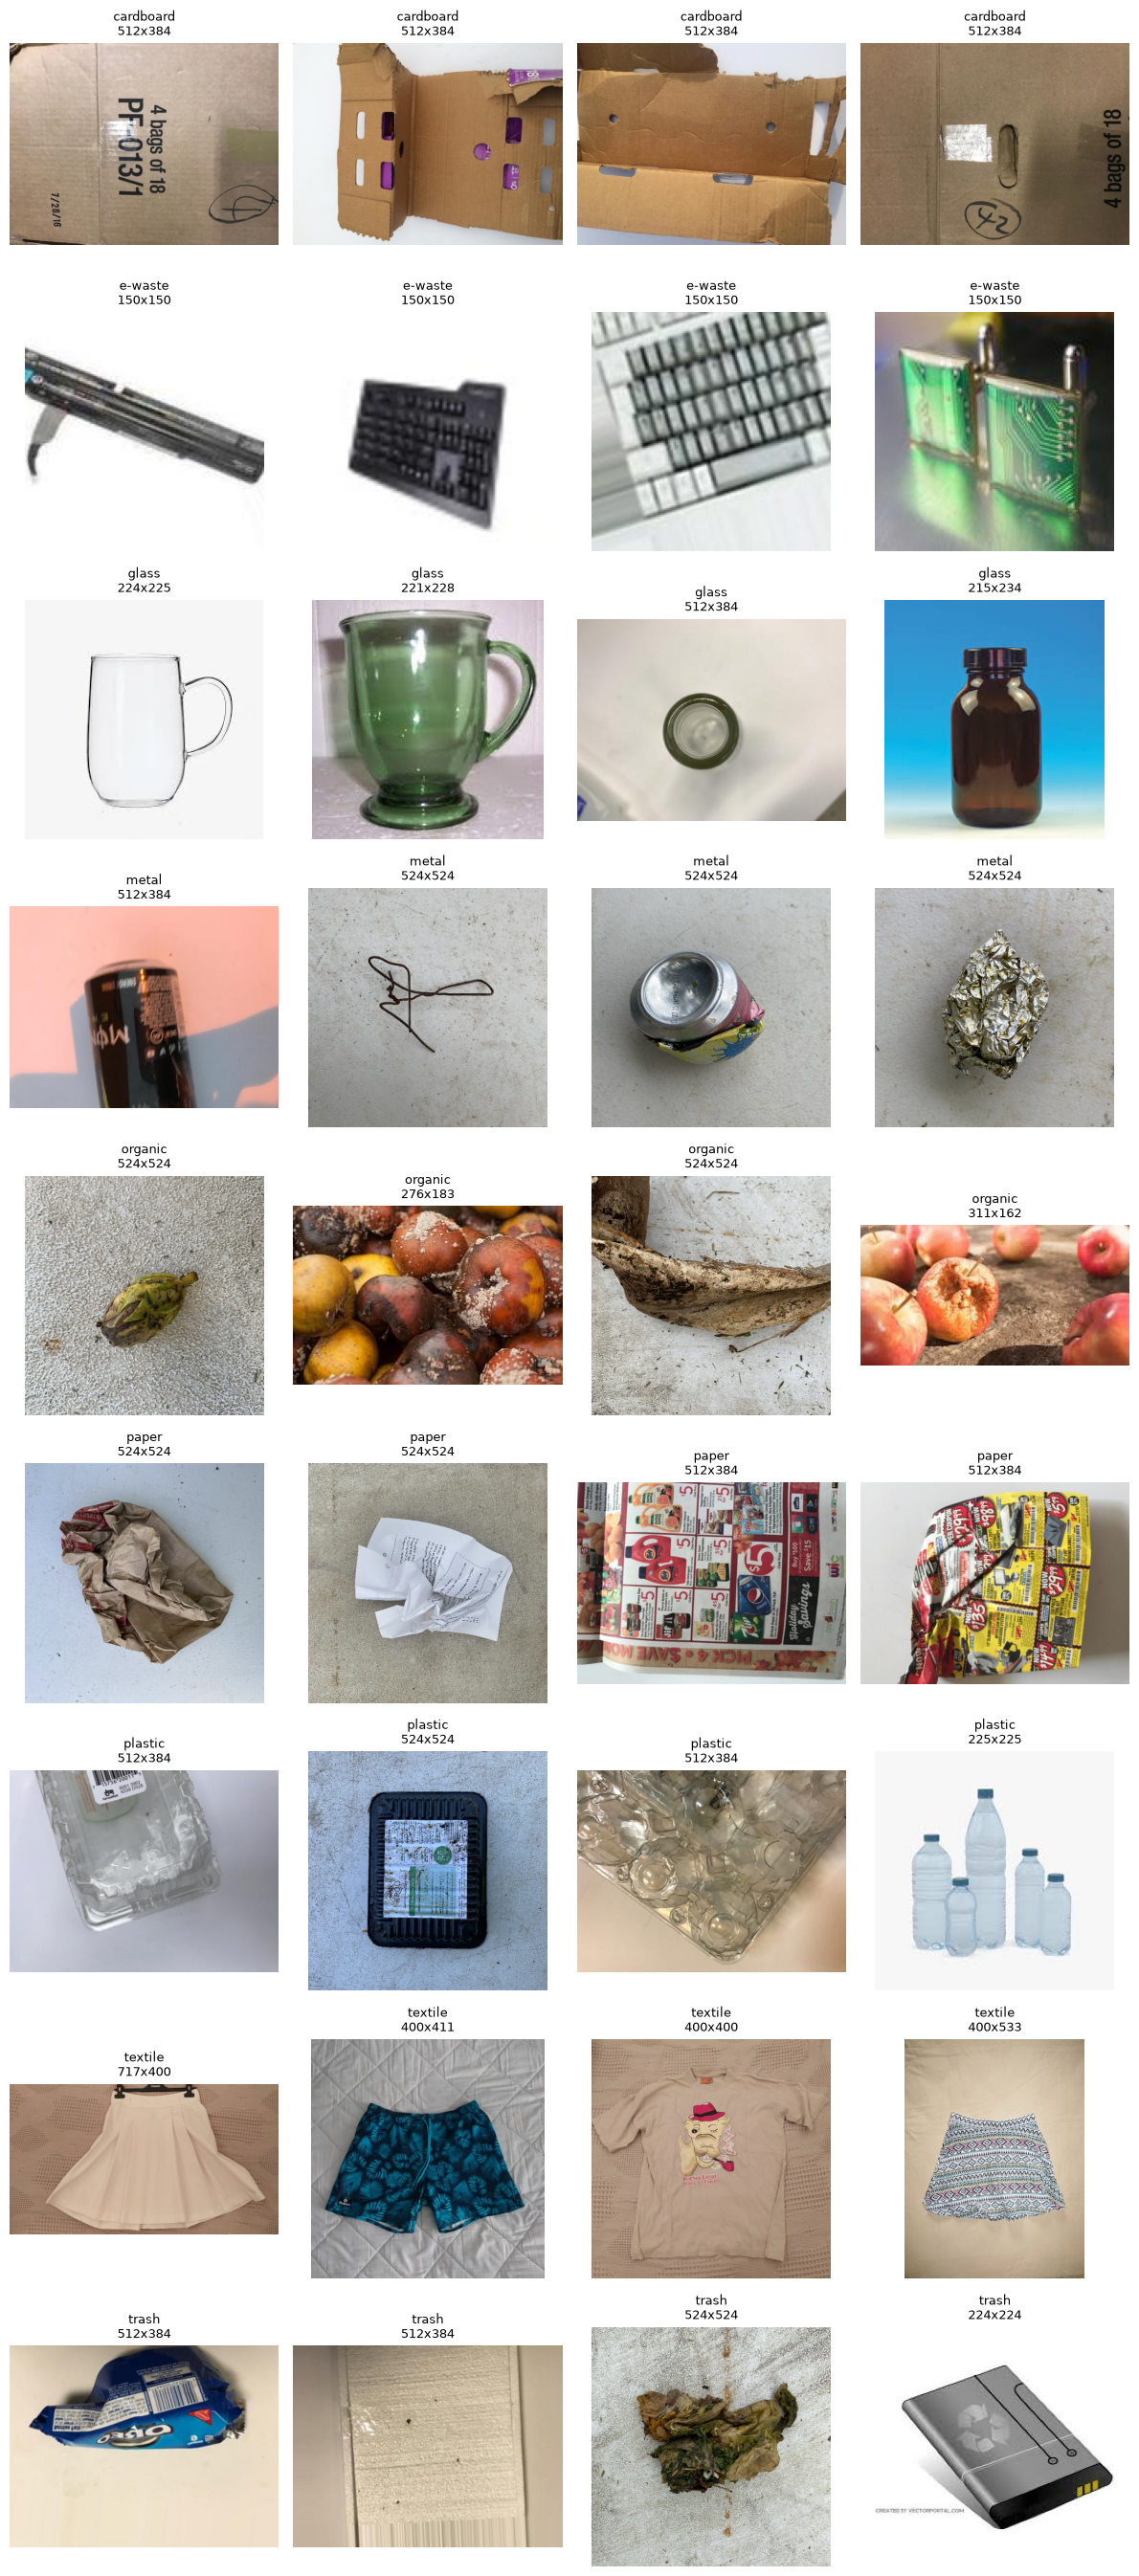

In [15]:
import random
from PIL import Image

data_dir = os.path.join(path, "new-dataset-trash-type-v2")
classes = sorted(d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)))
image_exts = (".jpg", ".jpeg", ".png")

print("Classes:", classes)
for c in classes:
    n = len([f for f in os.listdir(os.path.join(data_dir, c)) if f.lower().endswith(image_exts)])
    print(f"{c}: {n} images")

# Show random sample pictures, a few from each class
samples_per_class = 4
fig, axes = plt.subplots(len(classes), samples_per_class, figsize=(samples_per_class * 3, len(classes) * 3))

for row, c in enumerate(classes):
    class_dir = os.path.join(data_dir, c)
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(image_exts)]
    for col, fname in enumerate(random.sample(files, samples_per_class)):
        img = Image.open(os.path.join(class_dir, fname))
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_title(f"{c}\n{img.size[0]}x{img.size[1]}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

As we can see from the data its a mix of realworld trash pictures and also the professionally taken pictures.

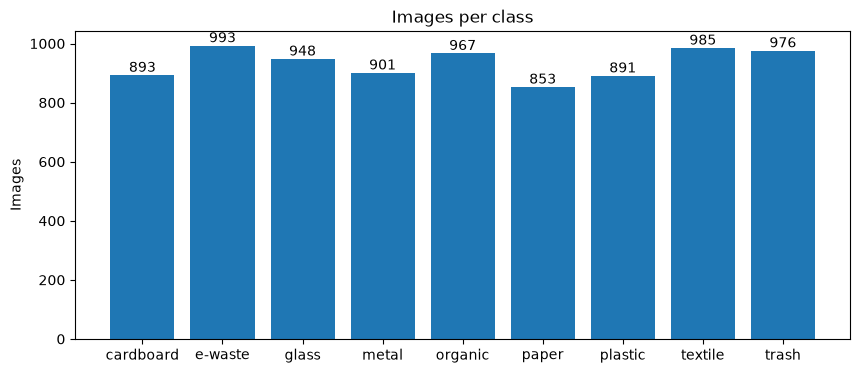

In [18]:
counts = [len(os.listdir(os.path.join(data_dir, c))) for c in classes]
plt.figure(figsize=(10, 4))
bars = plt.bar(classes, counts)
plt.bar_label(bars)
plt.ylabel("Images")
plt.title("Images per class")
plt.show()

## Data Preparation

After taking a look at the data we need to resize the data to our desired size. We chose to have it at 224x224 pixels so we can use the same data also in a pretrained CNN model. After resizing we also split the data into 3 parts: 70% for training, 15% for validation and the rest for testing. This is a fully automatic pipeline and anyone can run it after loading the notebook.

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

#load the downlaoded directory
data_dir = os.path.join(path, "new-dataset-trash-type-v2")

# Loads the images, resizes them to 224x224 and splits 70% train / 30% held out
train_ds, holdout_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="both",
    seed=42,
    shuffle=True,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    crop_to_aspect_ratio=True,
)
class_names = train_ds.class_names

# split the validation dataset in half so we get validation- and testset
n = holdout_ds.cardinality().numpy()
val_ds = holdout_ds.take(n // 2)
test_ds = holdout_ds.skip(n // 2)

images, labels = next(iter(train_ds))
print("Images:", images.shape)
print("Labels:", labels.shape)

Found 8407 files belonging to 9 classes.
Using 5885 files for training.
Using 2522 files for validation.
Images: (32, 224, 224, 3)
Labels: (32,)


Here we can see how the pictures look after downscaling or upscaling depending on the resolution of the picture before:

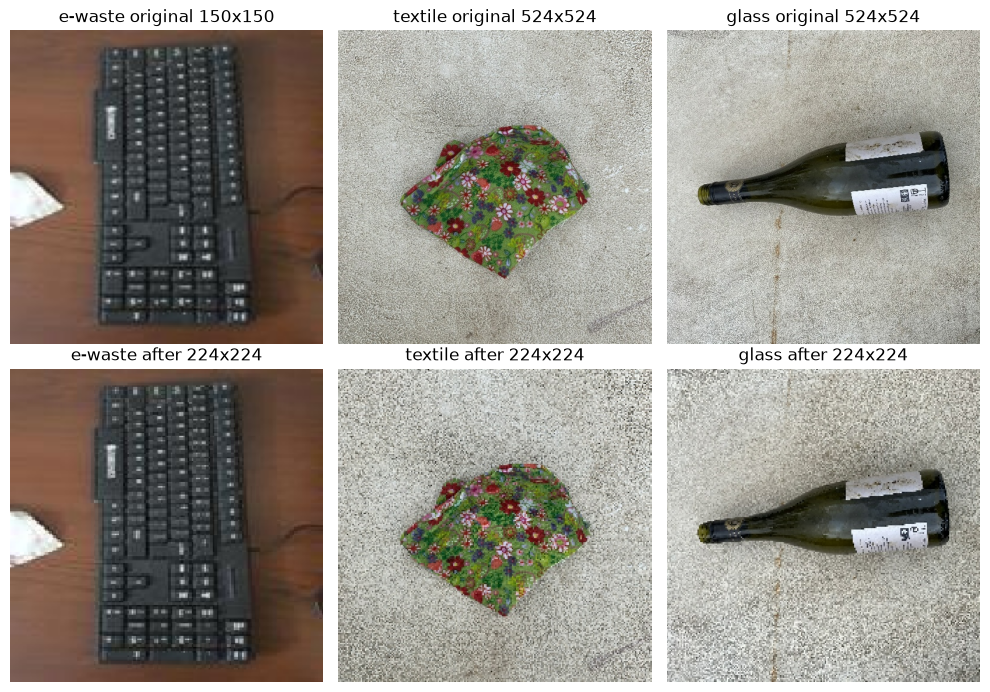

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for col, c in enumerate(["e-waste", "textile", "glass"]):
    p = os.path.join(data_dir, c, sorted(os.listdir(os.path.join(data_dir, c)))[0])
    orig = Image.open(p)
    resized = keras.utils.load_img(p, target_size=IMG_SIZE, keep_aspect_ratio=True)
    axes[0, col].imshow(orig);    axes[0, col].set_title(f"{c} original {orig.size[0]}x{orig.size[1]}")
    axes[1, col].imshow(resized); axes[1, col].set_title(f"{c} after 224x224")
    for ax in axes[:, col]: ax.axis("off")
plt.tight_layout()
plt.show()